# One sentence to a Hertzsprung–Russell diagram

This demo gives Augplot a stellar table with colour, brightness, and class labels, plus one short plotting request. Inspect the generated figure and Python to judge the one-shot result.

**Setup:** Install Augplot as in the [quick start](../README.md#quick-start), select that Python kernel, and have an OpenAI API key ready. The catalog download and model call need internet access. Generated Python runs locally after validation, without an OS sandbox.

In [6]:
import os
from getpass import getpass

import pandas as pd

import augplot as ap

os.environ["AUGPLOT_MODEL"] = "openai/gpt-6-sol"
if not os.getenv("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")

## Load an open stellar catalog

The [HYG Database v4.1](https://github.com/astronexus/HYG-Database/tree/main/hyg/CURRENT) by astronexus is licensed [CC BY-SA 4.0](https://github.com/astronexus/HYG-Database/blob/main/LICENSE). Its ci field is B−V colour index, absmag is absolute visual magnitude, and spect contains catalog spectral labels. The notebook downloads the catalog directly; no data file is bundled.

In [7]:
catalog_url = (
    "https://raw.githubusercontent.com/astronexus/HYG-Database/main/"
    "hyg/CURRENT/hygdata_v41.csv"
)
catalog = pd.read_csv(
    catalog_url, usecols=["id", "dist", "mag", "absmag", "ci", "spect"]
)
print(f"Downloaded {len(catalog):,} catalog rows")

Downloaded 119,626 catalog rows


## Prepare the plotting columns and class labels

Exclude the catalog's distance sentinel (≥ 100,000 pc, meaning missing or dubious parallax). Combine bright stars (apparent magnitude ≤ 6.5) with nearby stars (distance ≤ 75 pc), then use a stated display range of B−V from −0.4 to 2.4 mag and absolute V magnitude from −8 to 17 mag. Parse only unambiguous spectral labels into luminosity classes; all other stars remain Unclassified. Preserve case in white-dwarf labels: uppercasing a `dM` label would incorrectly turn it into a `D*` white dwarf. Relative V-band luminosity uses the [Sun's absolute visual magnitude of 4.83](https://nssdc.gsfc.nasa.gov/planetary/factsheet/sunfact.html); it is not bolometric luminosity. Any class guide curves should summarize labeled catalog stars, not imply exact physical boundaries. This is a visual demonstration sample, not a population-complete survey. The cell reports how many selected rows fall outside the range.

In [8]:
usable = catalog.dropna(subset=["dist", "mag", "absmag", "ci"])
usable = usable[usable["dist"] < 100000]
selected = usable[(usable["mag"] <= 6.5) | (usable["dist"] <= 75)]
in_range = selected[
    selected["ci"].between(-0.4, 2.4)
    & selected["absmag"].between(-8, 17)
]
raw_spectral_type = in_range["spect"].fillna("").str.strip()
spectral_type = raw_spectral_type.str.upper()
class_patterns = {
    "White dwarfs": r"^D[A-Za-z0-9.]*$",
    "Supergiants": r"^[OBAFGKM][0-9.]*I(?:A|B|AB)?$",
    "Bright giants": r"^[OBAFGKM][0-9.]*II$",
    "Giants": r"^[OBAFGKM][0-9.]*III$",
    "Subgiants": r"^[OBAFGKM][0-9.]*IV$",
    "Main sequence": r"^[OBAFGKM][0-9.]*V$",
}
stellar_class = pd.Series("Unclassified", index=in_range.index)
for label, pattern in class_patterns.items():
    labels = raw_spectral_type if label == "White dwarfs" else spectral_type
    stellar_class.loc[labels.str.fullmatch(pattern)] = label
stars = (
    in_range.rename(
        columns={
            "ci": "B_minus_V_color_index_mag",
            "absmag": "absolute_V_magnitude_mag",
        }
    )[["B_minus_V_color_index_mag", "absolute_V_magnitude_mag"]]
    .assign(stellar_class=stellar_class)
    .reset_index(drop=True)
)
stars["relative_V_band_luminosity_solar"] = 10 ** (
    0.4 * (4.83 - stars["absolute_V_magnitude_mag"])
)
print(f"Selected {len(selected):,} stars; plotting {len(stars):,}")
print(f"Outside the stated display range: {len(selected) - len(stars):,}")
print(stars["stellar_class"].value_counts().to_string())
stars.head()

Selected 21,656 stars; plotting 21,636
Outside the stated display range: 20
stellar_class
Unclassified     11766
Main sequence     5862
Giants            2748
Subgiants          855
Bright giants      150
White dwarfs       136
Supergiants        119


,B_minus_V_color_index_mag,absolute_V_magnitude_mag,stellar_class,relative_V_band_luminosity_solar
0,0.656,4.850,Main sequence,0.981748
1,0.999,5.866,Main sequence,0.385123
2,1.336,8.607,Unclassified,0.030846
3,0.740,5.828,Unclassified,0.398841
4,1.567,7.773,Unclassified,0.066497


## Ask once

The plotting prompt is a single sentence. It asks for the reference's dark star field, smooth magenta class guides with labels on the chart, and both brightness scales. Curves should follow only color ranges supported by their class data. Augplot opens a notebook input field only if the model asks for an essential choice; otherwise this makes one plotting request.

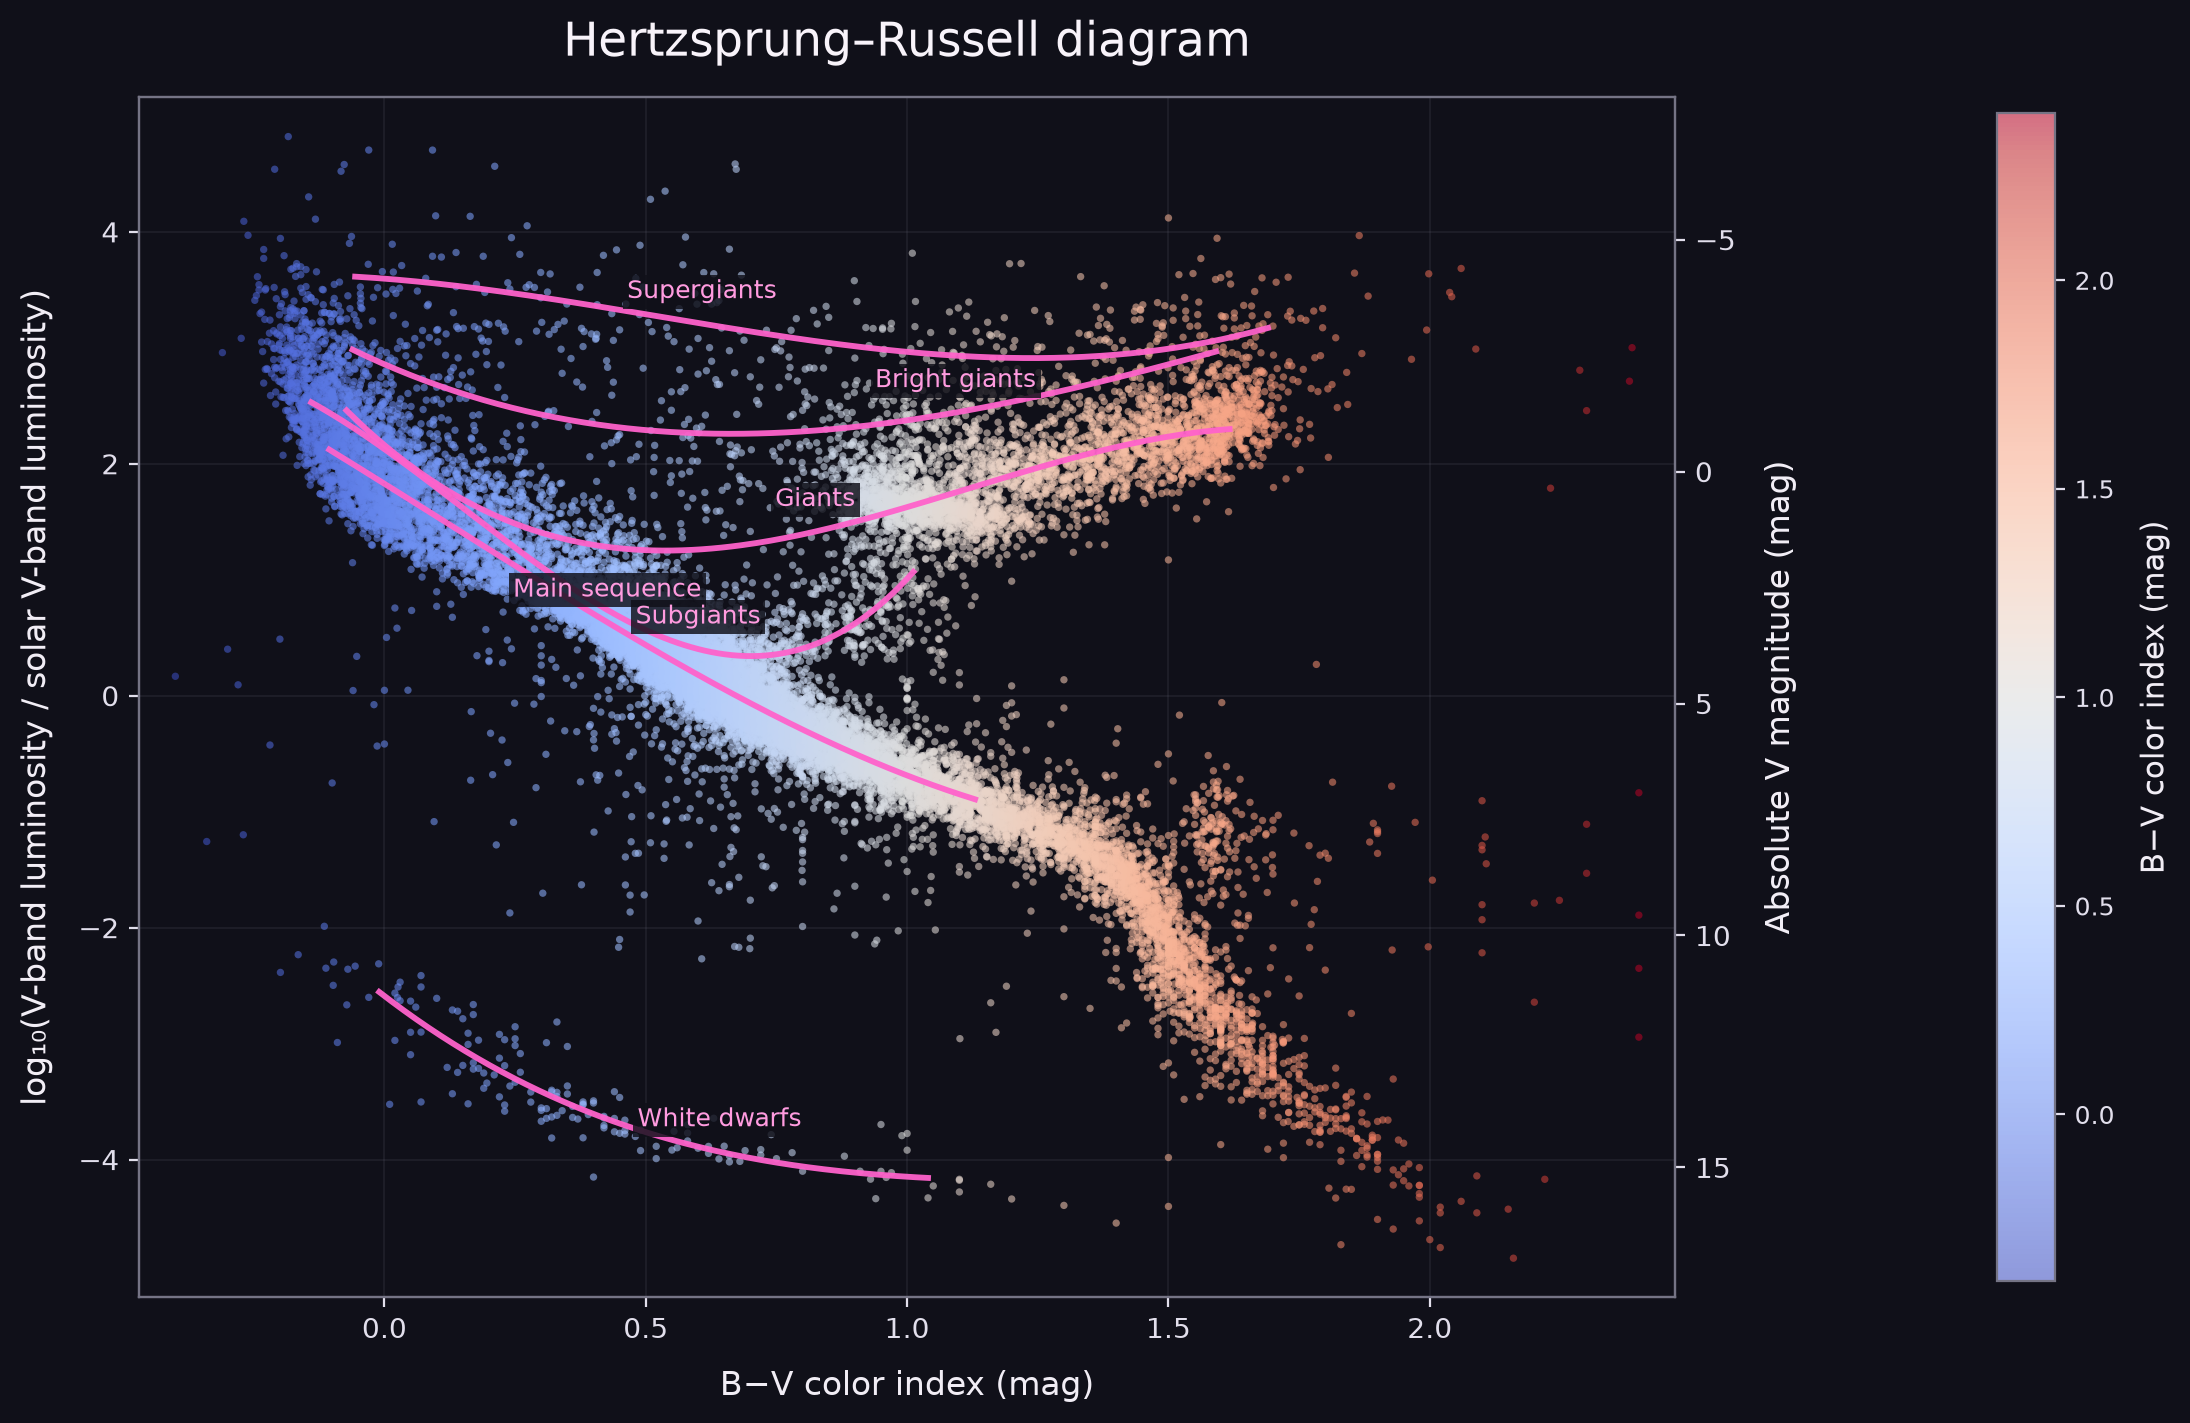

In [9]:
request = (
    "Make a classic dark H–R diagram of all stars colored by B−V, with log V-band "
    "luminosity left and magnitude right, plus smooth magenta low-degree curves fitted "
    "to binned medians for main sequence, subgiants, giants, bright giants, "
    "supergiants, and white dwarfs, directly labeled over populated color ranges."
)
chart = ap.plot(stars, prompt=request, backend="matplotlib")

## Inspect the one-shot result

A good observational H–R diagram should put B−V colour on the horizontal axis, show the main sequence and white dwarfs as distinct regions, and put brighter stars higher on both V-band brightness scales. Smooth class guides should stay within populated ranges and read as empirical guides, not exact physical boundaries. Review the figure and generated function below; the notebook does not substitute a hand-written plot.

In [5]:
from IPython.display import Code, display

print(chart.explanation)
print("Reused cached code:", chart.cache_hit)
display(Code(chart.code, language="python"))

Dark H–R diagram of all stars colored by B−V. Magenta curves fit low-degree polynomials to binned median log V-band luminosities for each stellar class with sufficient data; curves are limited to populated color ranges. The magnitude axis uses the median luminosity–magnitude offset in the supplied data.
Reused cached code: True


def plot_data(data, *, title=None, figsize=None):
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    df = data.copy()
    x_col = 'B_minus_V_color_index_mag'
    m_col = 'absolute_V_magnitude_mag'
    l_col = 'relative_V_band_luminosity_solar'
    needed = [x_col, m_col, l_col, 'stellar_class']
    missing = [col for col in needed if col not in df.columns]
    if missing:
        raise ValueError('Missing required columns: ' + ', '.join(missing))

    for col in [x_col, m_col, l_col]:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.loc[
        np.isfinite(df[x_col]) & np.isfinite(df[m_col]) &
        np.isfinite(df[l_col]) & (df[l_col] > 0)
    ].copy()
    if df.empty:
        raise ValueError('No stars have finite B−V and magnitude and positive V-band luminosity.')

    df['log_l'] = np.log10(df[l_col])
    solar_magnitude = float(np.median(df[m_col] + 2.5 * df['log_l']))
    classes = df['stellar_class'].fillna('').astype(str).str.lower().str.strip()
    categories = [
        ('Main sequence', classes.str.contains('main sequence', regex=False)),
        ('Subgiants', classes.str.contains('subgiant', regex=False)),
        ('Giants', classes.str.contains('giant', regex=False) &
         ~classes.str.contains('subgiant', regex=False) &
         ~classes.str.contains('bright giant', regex=False) &
         ~classes.str.contains('supergiant', regex=False)),
        ('Bright giants', classes.str.contains('bright giant', regex=False)),
        ('Supergiants', classes.str.contains('supergiant', regex=False)),
        ('White dwarfs', classes.str.contains('white dwarf', regex=False)),
    ]

    fig, ax = plt.subplots(figsize=figsize if figsize is not None else (11, 7), layout='constrained')
    fig.patch.set_facecolor('#101019')
    ax.set_facecolor('#101019')
    ax.tick_params(colors='#e2dfec', labelsize=10)
    for spine in ax.spines.values():
        spine.set_color('#757485')
    ax.grid(color='#777487', alpha=0.16, linewidth=0.6)
    ax.set_axisbelow(True)

    dots = ax.scatter(
        df[x_col], df['log_l'], c=df[x_col], cmap='coolwarm',
        vmin=float(df[x_col].min()), vmax=float(df[x_col].max()),
        s=7, alpha=0.57, edgecolors='none', rasterized=True, zorder=2
    )

    label_positions = {
        'Main sequence': 0.43, 'Subgiants': 0.64,
        'Giants': 0.53, 'Bright giants': 0.70,
        'Supergiants': 0.38, 'White dwarfs': 0.62
    }
    for name, mask in categories:
        group = df.loc[mask, [x_col, 'log_l']].copy()
        if len(group) < 9 or group[x_col].nunique() < 3:
            continue
        left = float(group[x_col].quantile(0.02))
        right = float(group[x_col].quantile(0.98))
        group = group.loc[group[x_col].between(left, right)].copy()
        if len(group) < 9 or left >= right:
            continue
        number_bins = min(22, max(8, int(np.sqrt(len(group)) / 2)))
        group['bin'] = pd.cut(group[x_col], bins=np.linspace(left, right, number_bins + 1), include_lowest=True)
        medians = group.groupby('bin', observed=True)[[x_col, 'log_l']].median()
        medians['count'] = group.groupby('bin', observed=True).size()
        medians = medians.loc[medians['count'] >= max(2, int(len(group) * 0.01))].sort_values(x_col)
        if len(medians) < 3:
            continue
        degree = min(3, len(medians) - 2)
        coefficients = np.polyfit(medians[x_col].to_numpy(), medians['log_l'].to_numpy(), degree)
        curve_x = np.linspace(float(medians[x_col].min()), float(medians[x_col].max()), 180)
        curve_y = np.polyval(coefficients, curve_x)
        ax.plot(curve_x, curve_y, color='#ff62cb', linewidth=2.1, alpha=0.95, zorder=4)
        label_x = float(curve_x[round((len(curve_x) - 1) * label_positions[name])])
        label_y = float(np.polyval(coefficients, label_x))
        ax.annotate(
            name, (label_x, label_y), xytext=(0, 7), textcoords='offset points',
            ha='center', va='bottom', f

## Save & Reuse the chart as ordinary Python

Export the plotting function to `augplot_utils.py` and call it directly on the Biscoe subset.


In [10]:
chart.to_python(function_name="h_r_diagram")

# With '.' on your Python import path:
from augplot_utils import h_r_diagram
fig = h_r_diagram(your_data)
fig


PosixPath('augplot_utils.py')

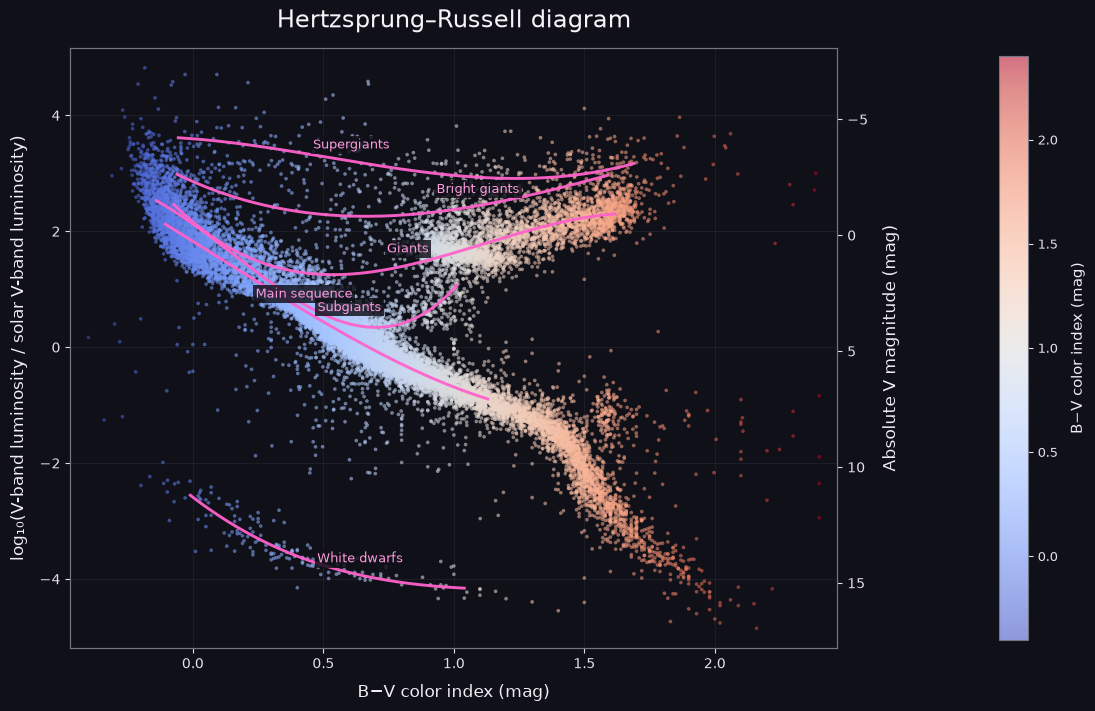

In [ ]:
from augplot_utils import h_r_diagram

fig = h_r_diagram(stars)
fig